# Exploratory Data Analysis: Stock Capitalization and PEG

A concise overview of data quality, distributions, extreme values, and feature relationships. Results are displayed inline; no files are exported.

## 1. Data Overview

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "data/equity_data.csv").exists() else Path.cwd().parent
df = pd.read_csv(ROOT / "data/equity_data.csv")
columns = ["Market_capital", "PEG ratio"]
print(f"Rows: {len(df):,} | Columns: {df.shape[1]}")
display(df.head())

Rows: 1,958 | Columns: 3


,Ticker,Market_capital,PEG ratio
0,RLJ,2.023031e+09,4.680005
1,FVR,5.152375e+08,NaN
2,BKD,2.214870e+09,NaN
3,RRR,5.268382e+09,6.189660
4,IVT,2.478155e+09,2.987124


**Finding:** The dataset contains 1,958 stocks and three columns: ticker, market capitalization, and PEG ratio. Ticker identifies stocks; the two numeric columns are the model features.

## 2. Duplicates and Missing Values

In [2]:
print(f"Duplicate rows: {df.duplicated().sum():,}")
print(f"Duplicate tickers: {df['Ticker'].duplicated().sum():,}")
missing = pd.DataFrame({
    "Missing count": df.isna().sum(),
    "Missing percent": df.isna().mean().mul(100).round(2),
})
display(missing)

Duplicate rows: 0
Duplicate tickers: 0


,Missing count,Missing percent
Ticker,0,0.0
Market_capital,0,0.0
PEG ratio,797,40.7


**Finding:** There are no duplicate rows or tickers. PEG is missing for 797 stocks (40.70%); ticker and market capitalization have no missing values.

## 3. Descriptive Statistics

In [3]:
display(df[columns].describe(percentiles=[.25, .5, .75, .95, .99]).T)

,count,mean,std,min,25%,50%,75%,95%,99%,max
Market_capital,1958.0,1.838728e+09,1.996305e+09,4.704041e+06,4.181133e+08,1.063996e+09,2.604428e+09,5.880965e+09,8.953323e+09,1.458955e+10
PEG ratio,1161.0,1.024929e+01,9.147316e+01,3.873000e-03,5.205860e-01,1.492798e+00,4.047014e+00,3.066762e+01,9.630457e+01,2.921253e+03


**Finding:** Median market capitalization is approximately 1.06 billion in source units. PEG has a median of 1.49 and a mean of 10.25, indicating a long upper tail; its maximum is 2,921.25.

## 4. Feature Distributions

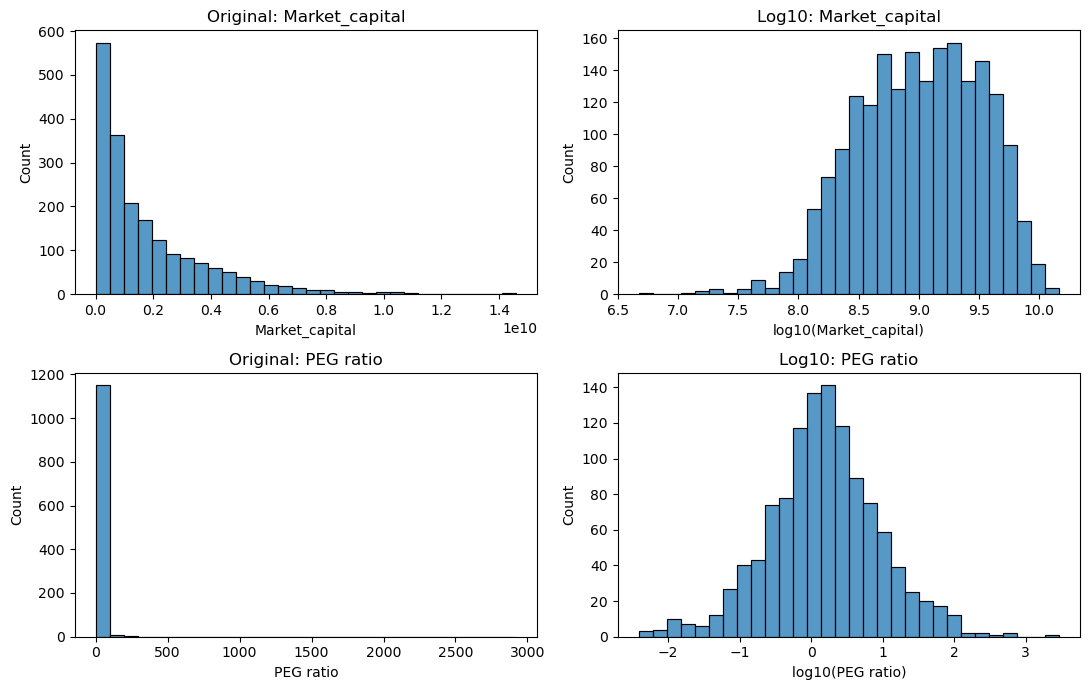

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, col in enumerate(columns):
    x = df[col].dropna()
    sns.histplot(x, bins=30, ax=axes[i, 0])
    axes[i, 0].set_title(f"Original: {col}")
    sns.histplot(np.log10(x[x > 0]), bins=30, ax=axes[i, 1])
    axes[i, 1].set_title(f"Log10: {col}")
    axes[i, 1].set_xlabel(f"log10({col})")
plt.tight_layout()
plt.show()

**Finding:** Both features are right-skewed, especially PEG. The log10 views make the central distributions easier to see and reduce the visual dominance of large observations.

## 5. Boxplots and Extreme Values

Boxplots show the median, interquartile range, and observations beyond the standard 1.5 × IQR whiskers. Points beyond the whiskers are potential outliers, not necessarily data errors.

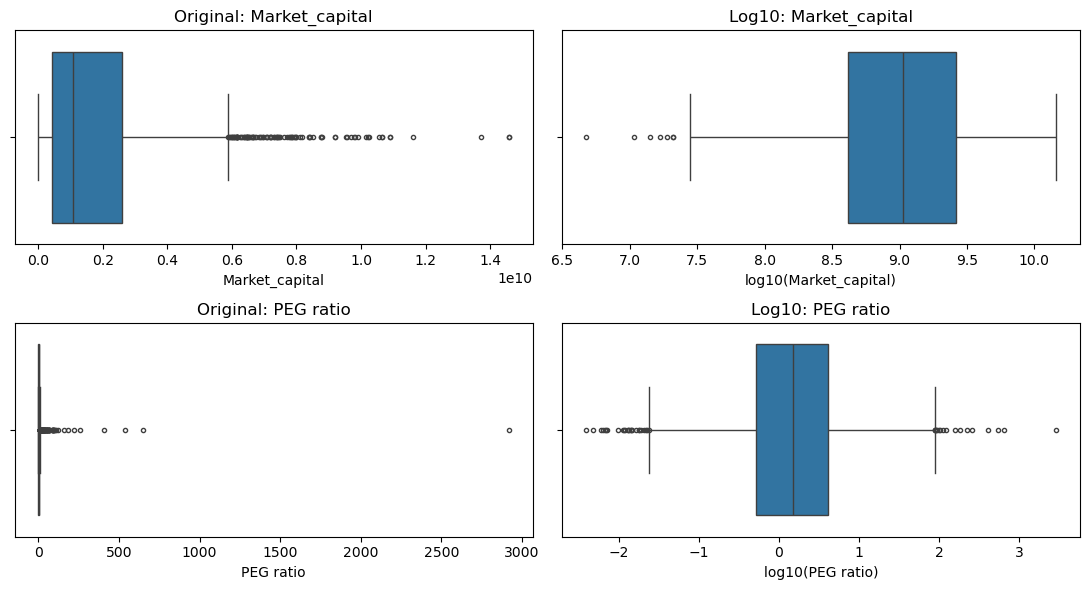

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for i, col in enumerate(columns):
    x = df[col].dropna()
    sns.boxplot(x=x, ax=axes[i, 0], flierprops={"markersize": 3})
    axes[i, 0].set_title(f"Original: {col}")
    sns.boxplot(x=np.log10(x[x > 0]), ax=axes[i, 1], flierprops={"markersize": 3})
    axes[i, 1].set_title(f"Log10: {col}")
    axes[i, 1].set_xlabel(f"log10({col})")
plt.tight_layout()
plt.show()

**Finding:** The raw PEG boxplot is compressed by very large upper-tail values. Log10 boxplots reveal the central spread and both tails more clearly. Outlier flags depend on the scale used; all observations are retained in this EDA.

## 6. Feature Relationships

,Measure,Correlation
0,"Pearson, raw",-0.013535
1,"Pearson, log10",0.033071
2,Spearman,0.027608


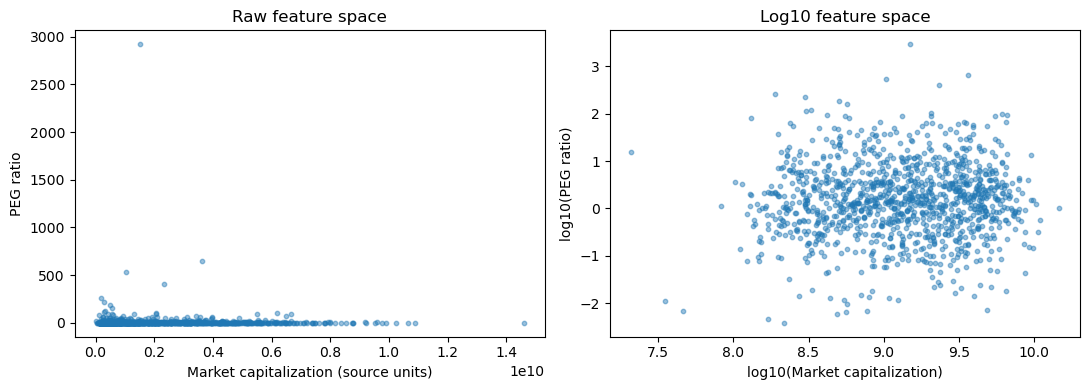

In [6]:
complete = df[columns].dropna()
log_features = np.log10(complete)
correlations = pd.DataFrame([
    {"Measure": "Pearson, raw", "Correlation": complete[columns[0]].corr(complete[columns[1]])},
    {"Measure": "Pearson, log10", "Correlation": log_features[columns[0]].corr(log_features[columns[1]])},
    {"Measure": "Spearman", "Correlation": complete[columns[0]].rank().corr(complete[columns[1]].rank())},
])
display(correlations)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(complete[columns[0]], complete[columns[1]], s=10, alpha=.45)
axes[0].set(xlabel="Market capitalization (source units)", ylabel="PEG ratio", title="Raw feature space")
axes[1].scatter(log_features[columns[0]], log_features[columns[1]], s=10, alpha=.45)
axes[1].set(xlabel="log10(Market capitalization)", ylabel="log10(PEG ratio)", title="Log10 feature space")
plt.tight_layout()
plt.show()

**Finding:** Raw Pearson (−0.014), log10 Pearson (0.033), and Spearman (0.028) correlations are close to zero, showing little linear or monotonic association between the features. Their different scales and extreme values support comparing log transformation and standardization before distance-based modeling.